# Phase 10: Benchmark Backtesting Engine

**Project:** Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market  
**Phase:** 10  
**Authoritative Inputs:**  
- Aligned Historical Closing Prices: `data/processed/aligned/` (`nifty_{auto,bank,fmcg,it,metal,pharma,50}_aligned.csv`)
- Benchmark Engine Module: `src/benchmark_backtest.py`
- Strategy Backtesting Parquet Artifacts: `results/portfolio_backtest/daily_simulation_{1A,1B,2A,2B}.parquet`

---

### Scope & Benchmark Specifications
1. **Benchmark A — NIFTY 50 Price Index Buy & Hold:**
   - Initial NAV = 1.0 on inception date (`2019-10-31`).
   - 100% allocation to NIFTY 50 throughout all 1,686 return intervals.
   - No subsequent rebalancing, zero turnover, zero transaction costs ($c = 0$ bps).
   - Gross NAV $\equiv$ Net NAV everywhere.
2. **Benchmark B — Equal-Weight Six-Sector Portfolio:**
   - Universe: Auto, Bank, FMCG, IT, Metal, Pharma.
   - Initial NAV = 1.0 on inception date (`2019-10-31`), initialized to 1/6 per sector.
   - Zero entry transaction costs at inception.
   - Monthly calendar rebalancing: Signal generated at final available trading session of each calendar month Close; executes at first trading session of following calendar month Close ($t+1$ Close).
   - Daily intra-month weight drift: $\tilde{w}_{s, t} = [w_{s, t-1} (1 + r_{s, t})] / [1 + R_{\text{gross}, t}]$.
   - Actual one-way turnover: $TO_{\text{actual}} = \frac{1}{2} \sum |1/6 - \tilde{w}_s|$.
   - Institutional transaction cost rate: 15 bps (0.0015) deducted from pre-trade net NAV.
   - Independent Gross NAV (0 bps) and Net NAV (15 bps) series.

## 1. Environment Setup and Imports

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import Phase 10 benchmark backtesting engine
from src.benchmark_backtest import (
    SECTOR_NAMES,
    ALL_BENCHMARK_ASSETS,
    DEFAULT_TRANSACTION_COST_RATE,
    EXPECTED_TOTAL_RETURN_INTERVALS,
    EXPECTED_TRAIN_RETURN_INTERVALS,
    EXPECTED_HOLDOUT_RETURN_INTERVALS,
    EXPECTED_TRAIN_START,
    EXPECTED_TRAIN_END,
    EXPECTED_HOLDOUT_START,
    EXPECTED_HOLDOUT_END,
    load_benchmark_prices,
    get_month_end_signal_dates,
    simulate_nifty50_benchmark,
    simulate_equal_weight_benchmark,
    run_all_benchmarks,
    compute_benchmark_metrics,
    generate_benchmark_metrics_table,
    save_benchmark_parquet,
    reload_and_verify_benchmark_parquet,
    run_benchmark_pipeline,
)

print("Environment initialized successfully.")
print(f"Project root: {project_root}")

Environment initialized successfully.
Project root: c:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery


## 2. Aligned Price Data Loading and Calendar Verification

Load the aligned closing price series and verify the month-end transition calendar.

In [2]:
price_df = load_benchmark_prices()
print(f"Loaded aligned prices: {price_df.shape[0]} sessions ({price_df.index.min().date()} to {price_df.index.max().date()})")
print(f"Assets present: {list(price_df.columns)}")

# Verify month-end signal dates
signal_dates = get_month_end_signal_dates(price_df.index)
sorted_signals = sorted(list(signal_dates))
print(f"\nTotal month-end rebalance signals: {len(sorted_signals)}")
print(f"First signal: {sorted_signals[0].date()} (executes on next session Close)")
print(f"Last signal:  {sorted_signals[-1].date()} (executes on next session Close)")

# Confirm inception date (2019-10-31) is NOT a signal date
assert pd.Timestamp("2019-10-31") not in signal_dates, "Inception date must not be a rebalance signal"
assert sorted_signals[0] == pd.Timestamp("2019-11-29"), "First signal must be 2019-11-29"

Loaded aligned prices: 1687 sessions (2019-10-31 to 2026-09-18)
Assets present: ['AUTO', 'BANK', 'FMCG', 'IT', 'METAL', 'PHARMA', 'NIFTY50']

Total month-end rebalance signals: 82
First signal: 2019-11-29 (executes on next session Close)
Last signal:  2026-08-31 (executes on next session Close)


## 3. Benchmark A: NIFTY 50 Price Index Buy & Hold Simulation

Execute simulation for Benchmark A across all 1,686 return intervals.

In [3]:
df_n50 = simulate_nifty50_benchmark(price_df)
print(f"Benchmark A (NIFTY 50 Buy & Hold) Simulation Summary:")
print(f"- Return intervals: {len(df_n50)}")
print(f"- Training intervals: {(df_n50['period'] == 'train').sum()}")
print(f"- Holdout intervals:  {(df_n50['period'] == 'holdout').sum()}")
print(f"- Final Gross NAV: {df_n50['gross_nav'].iloc[-1]:.4f} (+{(df_n50['gross_nav'].iloc[-1] - 1.0)*100:.2f}%)")
print(f"- Final Net NAV:   {df_n50['net_nav'].iloc[-1]:.4f} (+{(df_n50['net_nav'].iloc[-1] - 1.0)*100:.2f}%)")
print(f"- Gross == Net verification: {(df_n50['gross_nav'] == df_n50['net_nav']).all()}")

Benchmark A (NIFTY 50 Buy & Hold) Simulation Summary:
- Return intervals: 1686
- Training intervals: 1264
- Holdout intervals:  422
- Final Gross NAV: 1.9656 (+96.56%)
- Final Net NAV:   1.9656 (+96.56%)
- Gross == Net verification: True


## 4. Benchmark B: Equal-Weight Six-Sector Portfolio Simulation

Execute simulation for Benchmark B with monthly rebalancing at $t+1$ Close, dynamic intra-month weight drift, and 15 bps friction.

In [4]:
df_ew = simulate_equal_weight_benchmark(price_df, cost_rate=DEFAULT_TRANSACTION_COST_RATE)
print(f"Benchmark B (Equal-Weight 6-Sector) Simulation Summary:")
print(f"- Return intervals: {len(df_ew)}")
print(f"- Training intervals: {(df_ew['period'] == 'train').sum()}")
print(f"- Holdout intervals:  {(df_ew['period'] == 'holdout').sum()}")
print(f"- Monthly rebalances executed: {df_ew['rebalance_executed'].sum()}")
print(f"- Cumulative actual turnover: {df_ew['actual_turnover'].sum():.4f}")
print(f"- Cumulative transaction costs: {df_ew['transaction_cost'].sum():.4f}")
print(f"- Final Gross NAV: {df_ew['gross_nav'].iloc[-1]:.4f} (+{(df_ew['gross_nav'].iloc[-1] - 1.0)*100:.2f}%)")
print(f"- Final Net NAV:   {df_ew['net_nav'].iloc[-1]:.4f} (+{(df_ew['net_nav'].iloc[-1] - 1.0)*100:.2f}%)")

Benchmark B (Equal-Weight 6-Sector) Simulation Summary:
- Return intervals: 1686
- Training intervals: 1264
- Holdout intervals:  422
- Monthly rebalances executed: 82
- Cumulative actual turnover: 1.4911
- Cumulative transaction costs: 0.0041
- Final Gross NAV: 2.8110 (+181.10%)
- Final Net NAV:   2.8047 (+180.47%)


## 5. Benchmark Equity Curves and Drawdown Dynamics

Visualize cumulative NAV progression and drawdown profiles for both benchmarks.

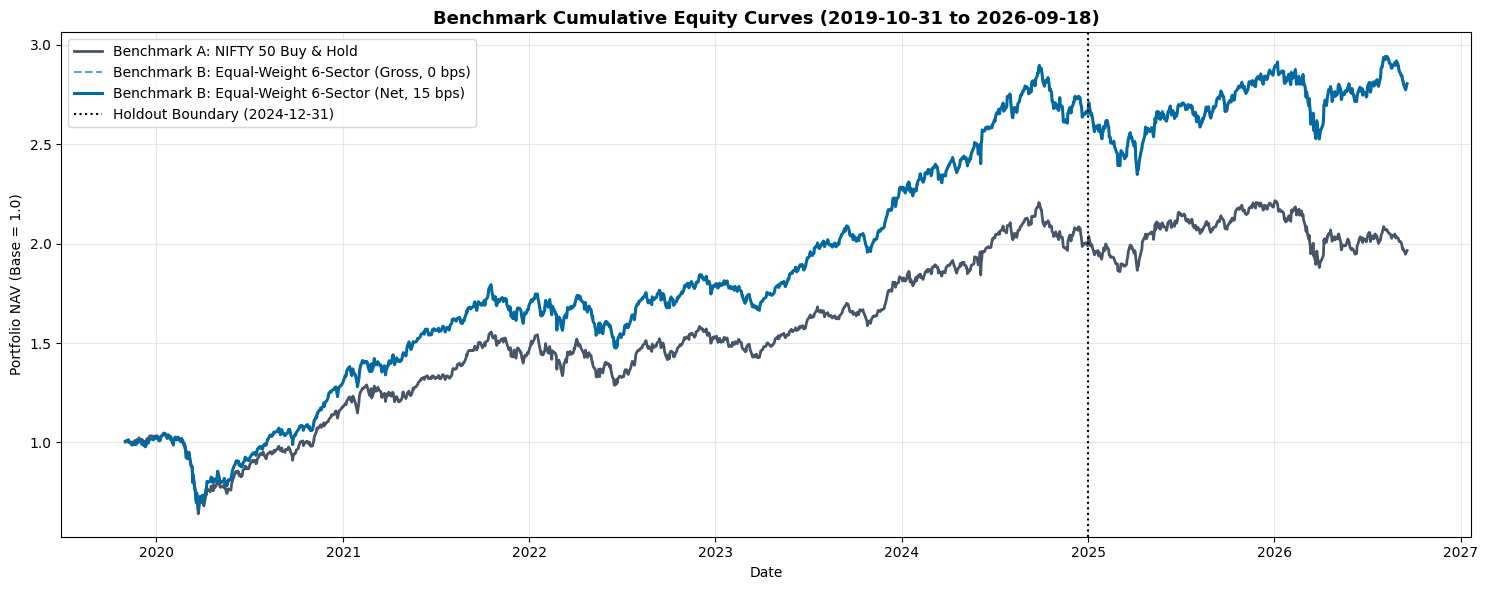

In [5]:
plt.figure(figsize=(15, 6))
plt.plot(df_n50.index, df_n50["net_nav"], label="Benchmark A: NIFTY 50 Buy & Hold", color="#475569", linewidth=2.0)
plt.plot(df_ew.index, df_ew["gross_nav"], label="Benchmark B: Equal-Weight 6-Sector (Gross, 0 bps)", color="#0284c7", linestyle="--", alpha=0.7)
plt.plot(df_ew.index, df_ew["net_nav"], label="Benchmark B: Equal-Weight 6-Sector (Net, 15 bps)", color="#0369a1", linewidth=2.2)

plt.axvline(pd.Timestamp("2024-12-31"), color="black", linestyle=":", label="Holdout Boundary (2024-12-31)")
plt.title("Benchmark Cumulative Equity Curves (2019-10-31 to 2026-09-18)", fontsize=13, fontweight="bold")
plt.ylabel("Portfolio NAV (Base = 1.0)")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

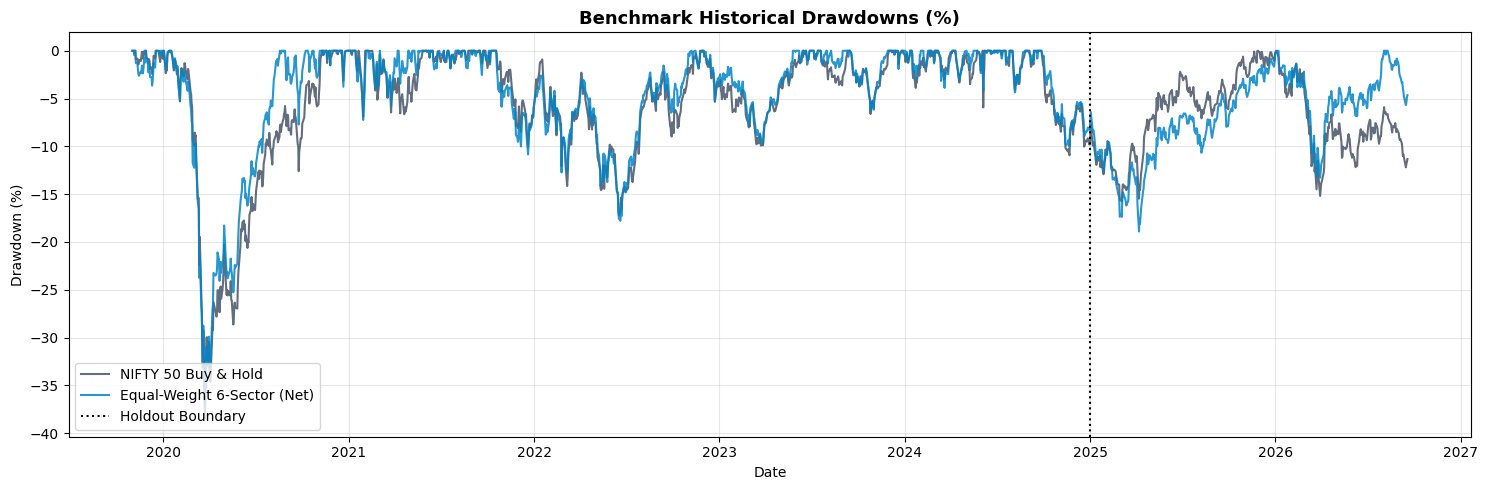

In [6]:
# Underwater Drawdown Comparison
plt.figure(figsize=(15, 5))

dd_n50 = (df_n50["net_nav"] - np.maximum.accumulate(df_n50["net_nav"])) / np.maximum.accumulate(df_n50["net_nav"]) * 100.0
dd_ew = (df_ew["net_nav"] - np.maximum.accumulate(df_ew["net_nav"])) / np.maximum.accumulate(df_ew["net_nav"]) * 100.0

plt.plot(df_n50.index, dd_n50, label="NIFTY 50 Buy & Hold", color="#475569", alpha=0.85)
plt.plot(df_ew.index, dd_ew, label="Equal-Weight 6-Sector (Net)", color="#0284c7", alpha=0.85)
plt.axvline(pd.Timestamp("2024-12-31"), color="black", linestyle=":", label="Holdout Boundary")

plt.title("Benchmark Historical Drawdowns (%)", fontsize=13, fontweight="bold")
plt.ylabel("Drawdown (%)")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()

## 6. Drift Dynamics and Monthly Turnover Analysis (Benchmark B)

Inspect the sector weight drift between rebalance dates and the actual monthly rebalance turnover.

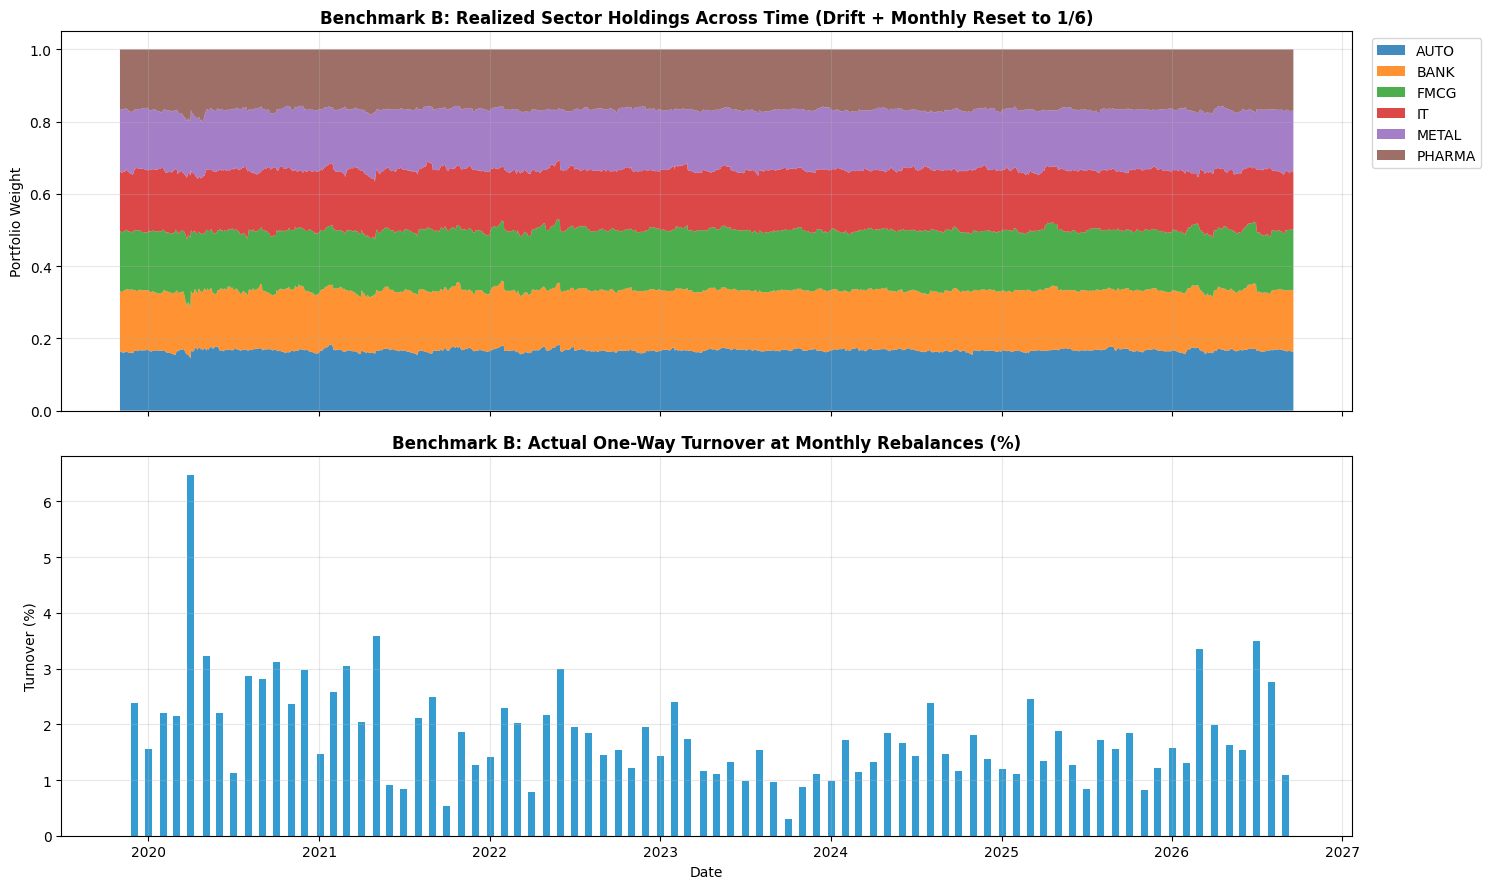

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# Stacked area of sector holdings
w_cols = [f"w_post_{s}" for s in SECTOR_NAMES]
ax1.stackplot(df_ew.index, [df_ew[col] for col in w_cols], labels=SECTOR_NAMES, alpha=0.85)
ax1.set_title("Benchmark B: Realized Sector Holdings Across Time (Drift + Monthly Reset to 1/6)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Portfolio Weight")
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax1.grid(True, alpha=0.3)

# Rebalance turnover spikes
rebal_df = df_ew[df_ew["rebalance_executed"]]
ax2.bar(rebal_df.index, rebal_df["actual_turnover"] * 100.0, width=15, color="#0284c7", alpha=0.8)
ax2.set_title("Benchmark B: Actual One-Way Turnover at Monthly Rebalances (%)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Turnover (%)")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Performance Metrics Summary Table

Compile quantitative performance, risk, and execution metrics across Training, Holdout, and Full periods.

In [8]:
simulations = {"NIFTY50": df_n50, "EQUAL_WEIGHT": df_ew}
metrics_table = generate_benchmark_metrics_table(simulations, validate_counts=True)

display_cols = [
    "benchmark_name", "period", "return_intervals", "total_return_net_pct", "cagr_net_pct",
    "cagr_drag_pct", "ann_volatility_pct", "sharpe_ratio", "sortino_ratio",
    "max_drawdown_pct", "rebalances_executed", "ann_actual_turnover",
]
print("Master Benchmark Performance Summary Table:")
print(metrics_table[display_cols].to_string(index=False))

Master Benchmark Performance Summary Table:
      benchmark_name  period  return_intervals  total_return_net_pct  cagr_net_pct  cagr_drag_pct  ann_volatility_pct  sharpe_ratio  sortino_ratio  max_drawdown_pct  rebalances_executed  ann_actual_turnover
    NIFTY50_BUY_HOLD   train              1264             99.073037     14.713159       0.000000           18.990537      0.819030       1.104035        -38.439852                    0             0.000000
    NIFTY50_BUY_HOLD holdout               422             -1.262013     -0.755546       0.000000           13.225443      0.008583       0.012284        -15.181809                    0             0.000000
    NIFTY50_BUY_HOLD    full              1686             96.560710     10.628707       0.000000           17.725677      0.659449       0.896060        -38.439852                    0             0.000000
EQUAL_WEIGHT_6SECTOR   train              1264            165.733835     21.512438       0.041101           18.066242      1.170

## 8. Apache Parquet Persistence and Parity Verification

Persist authoritative daily simulation records in Apache Parquet format and verify round-trip numerical parity.

In [9]:
saved_paths = save_benchmark_parquet(simulations)
audit_results = reload_and_verify_benchmark_parquet(saved_paths, original_simulations=simulations)

print("Apache Parquet Audit & Parity Verification:")
for b_key, a in audit_results.items():
    print(f"Benchmark {b_key}:")
    print(f"  - File: {a['path']}")
    print(f"  - Size: {a['size_bytes']:,} bytes")
    print(f"  - Rows: {a['rows']}")
    print(f"  - Columns: {a['columns']}")
    print(f"  - Train intervals: {a['train_intervals']}")
    print(f"  - Holdout intervals: {a['holdout_intervals']}")
    print(f"  - Numerical parity confirmed: {a['parity_verified']}")

print("\nPhase 10 Benchmark Backtesting Engine successfully verified and persisted.")

Apache Parquet Audit & Parity Verification:
Benchmark NIFTY50:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\portfolio_backtest\daily_simulation_benchmark_nifty50.parquet
  - Size: 154,508 bytes
  - Rows: 1686
  - Columns: 20
  - Train intervals: 1264
  - Holdout intervals: 422
  - Numerical parity confirmed: True
Benchmark EQUAL_WEIGHT:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\portfolio_backtest\daily_simulation_benchmark_equal_weight.parquet
  - Size: 614,804 bytes
  - Rows: 1686
  - Columns: 50
  - Train intervals: 1264
  - Holdout intervals: 422
  - Numerical parity confirmed: True

Phase 10 Benchmark Backtesting Engine successfully verified and persisted.
